In [2]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib import rc
import sys
import multiprocessing as mp
from scipy.optimize import curve_fit

#sys.setrecursionlimit(100000) milijon je preveč
rc({"text.usetex": True,
    'family': 'serif', 'serif': ['Computer Modern'],
    })
plt.rcParams.update({'font.size': 20})

In [3]:
def koren(število):
    '''aproksimacija korena
    aproksimacijsko število je i-1'''
    i=1
    r2 = i + (število-i*i)/(2*i)
    r1 = r2+1
    while r2 <= r1:
        r1 = r2
        i += 1
        r2 = i + (število-i*i)/(2*i)
    return r1

In [4]:
def E(h, alpha):
    Eh = 0
    for i in range(len(h)):
        Eh += alpha * h[i]
    for i in range(len(h)-1):
        Eh += 0.5*(h[i+1]-h[i])**2
    return Eh
def dE(h,alpha, sprememba, lega):
    dEh = sprememba**2 - sprememba*(h[lega+1]-2*h[lega]+h[lega-1]-alpha)
    return dEh
def E_upogib(h, alpha):#TEST
    Eh = 0
    for i in range(len(h)):
        Eh += alpha * h[i]
    for i in range(len(h)-1):
        Eh += 0.5*(h[i+1]-h[i])**2
    for i in range(1,len(h)-1):
        #Eh -= (h[i+1]-h[i-1])/2
        Eh += (h[i+1]-2*h[i]+h[i-1])
    return Eh
def metropolis(h, energija, alpha, beta, h_max):
    h_min=0
    h_old = h.copy()
    lega = np.random.randint(1, len(h)-1) #gibanje robnih ni mogoče
    premik = np.random.randint(0,2)
    #premik = 1 #le pomiki dol
    if premik == 0:
        h[lega] -= 1
    else:
        h[lega] += 1
    if h[lega] < h_max or h[lega] > h_min: #omejitev gibanja
        #metropolis(h_old, energija, m,k,d,T,max_calls)
        h = h_old # ne spremeni vrednosti - prazen klic
        energija_nova = energija
        metropolis.counter +=1
    else:
        energija_nova = E(h, alpha) #skupna E
        #E_spr = dE(h,alpha,premik,lega) #sprememba E, OK če nas ne zanima celotna
        if energija_nova > energija:
        #if E_spr > 0: #sprememba E
            u=np.random.random()
            if u > np.exp(-beta*(energija_nova-energija)):
                h = h_old #prazen klic!
                metropolis.counter +=1
    #             metropolis(h_old, energija, m,k,d,T,max_calls)
    # if metropolis.counter >= max_calls:
    #     return h_nov
    # else:
    #     metropolis(h_nov, energija, m,k,d,T,max_calls)
    return h, energija_nova
def ravnovesje(data):
    # n_step = 1000 #št intervalov
    # l = len(data)//n_step #dolžina intervala
    # stac = []
    # for i in range(0, len(data), l):
    #     avg1 = np.average(data[-(i-1)*l : -(i-0)*l-1])
    #     avg2 = np.average(data[-(i-2)*l : -(i-1)*l])
    #     print(data[-(i-1)*l : -(i-0)*l-1])
    #     if avg1 < 1.5*avg2:
    #         print('pass')
    #         stac.append(avg1)
    return np.average(data[-1000:-1])
def verižnica(x,a,b,c):
    #return a*np.cosh((x-(len(h)-1)/2)/a)+b
    return a*x**2 + b*x + c
def min_verižnice(n,a):
    return -a/4*n**2

In [5]:
def parallel_metropolis(h, energija, m, k, d, T, max_iterations=100): #ni ok
    num_processes = mp.cpu_count()
    pool = mp.Pool(processes=num_processes)
    
    results = []
    iterations_per_process = max_iterations // num_processes
    
    for _ in range(num_processes):
        h_copy = h.copy()
        result = pool.apply_async(metropolis, (h_copy, energija, m, k, d, T, iterations_per_process))
        results.append(result)
    
    pool.close()
    pool.join()
    
    final_result = results[0].get()
    for result in results[1:]:
        result_h = result.get()
        # Combine the results (for simplicity, let's say we take the result from the first process)
        final_result = result_h
    
    return final_result

1805

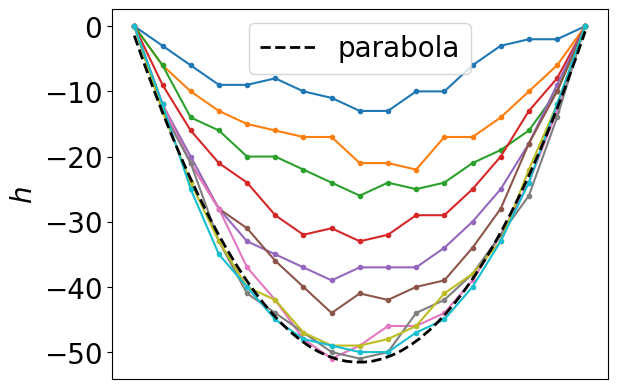

In [6]:
alpha=2
beta=1
h=np.zeros(17)
Ei = E(h,alpha)
metropolis.counter=0
energija = []
oblika = [[],[]]
n = 5000
for i in range(n):
    h, Ei = metropolis(h, Ei, alpha, beta, -180000)
    energija.append(Ei)
    if i%(n//10) == 0 and i!=0:
        oblika[0].append(h)
        oblika[1].append(i)
oblika[0].append(h)
oblika[1].append(i)
for i,j in zip(oblika[0], oblika[1]):
    plt.plot(i,'.-')

popt, _ = curve_fit(verižnica, np.array(range(len(h))), h)
x=np.linspace(0,len(h)-1)
plt.plot(x, verižnica(x,*popt), 'k--', label=f'parabola', linewidth=2)
plt.legend()
plt.xticks([]) 
plt.ylabel('$h$') 
#plt.legend(bbox_to_anchor=(1,1), ncol=1)
metropolis.counter #prazni klici
#plt.savefig('slike/konvergenca_metropolis_neomejen.pdf')
#ravnovesje(energija)

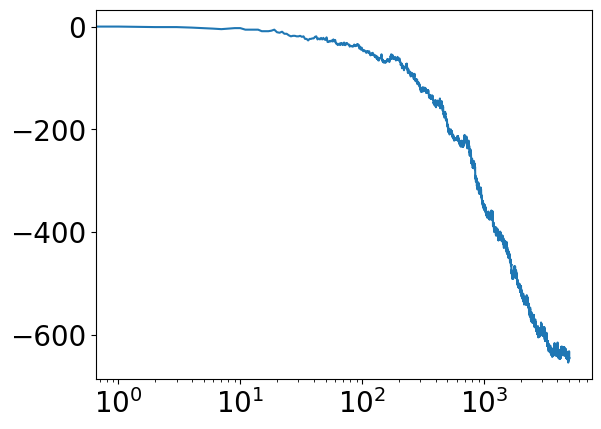

In [7]:
plt.plot(energija)
plt.xscale('log')

vpliv beta

Text(0, 0.5, '$E$')

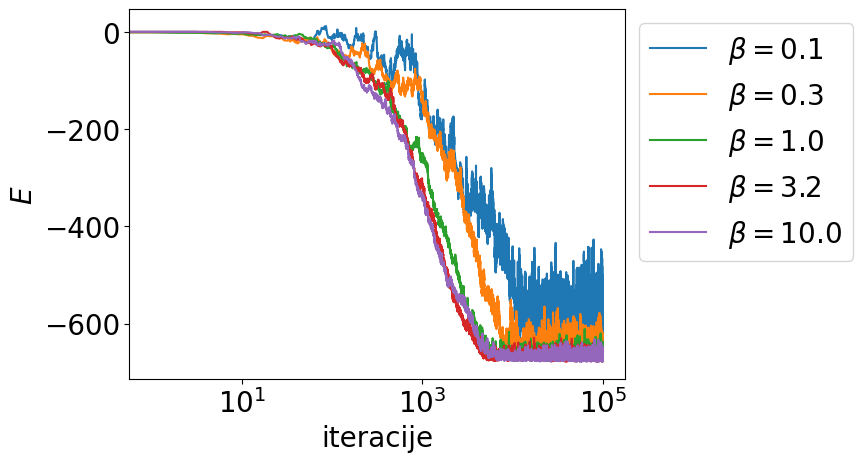

In [8]:
alpha=2
beta0=np.logspace(-1,1,5)
energija = []
oblika = np.array([])
iteracije = np.array([])
n = 100000
for beta in beta0:
    h=np.zeros(17)
    Ei = E(h,alpha)
    en=[E(h,alpha)]
    metropolis.counter=0
    for i in range(n):
        h, Ei = metropolis(h, Ei, alpha, beta, -np.inf)
        en.append(Ei)
        if i%(n//10) == 0 and i!=0:
            oblika = np.append(oblika, h, axis=0)
            #iteracije = np.append(iteracije, i)
    oblika = np.append(oblika, h, axis=0)
    iteracije = np.append(iteracije, i)
    energija.append(en)
for i in range(len(energija)):
    plt.plot(energija[i], '-', label=f'$\\beta = $'+str(round(beta0[i],1)))
plt.legend(bbox_to_anchor=(1,1))
plt.xscale('log')
plt.xlabel('iteracije')
plt.ylabel('$E$')
#plt.savefig('slike/vpliv_beta_neomejeno.pdf', bbox_inches='tight')

vpliv alpha

Text(0, 0.5, '$E$')

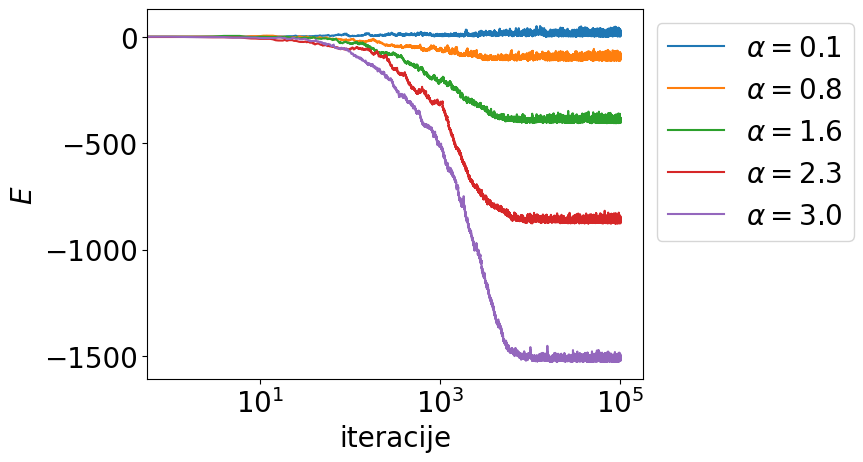

In [9]:
beta=1
alpha0=np.linspace(0.1,3,5)
energija = []
oblika = np.array([])
iteracije = np.array([])
n = 100000
for alpha in alpha0:
    h=np.zeros(17)
    Ei = E(h,alpha)
    en=[E(h,alpha)]
    metropolis.counter=0
    for i in range(n):
        h, Ei = metropolis(h, Ei, alpha, beta, -np.inf)
        en.append(Ei)
        if i%(n//10) == 0 and i!=0:
            oblika = np.append(oblika, h, axis=0)
            #iteracije = np.append(iteracije, i)
    oblika = np.append(oblika, h, axis=0)
    iteracije = np.append(iteracije, i)
    energija.append(en)
for i in range(len(energija)):
    plt.plot(energija[i], '-', label=f'$\\alpha = $'+str(round(alpha0[i],1)))
plt.legend(bbox_to_anchor=(1,1))
plt.xscale('log')
plt.xlabel('iteracije')
plt.ylabel('$E$')
#plt.savefig('slike/vpliv_alpha.pdf', bbox_inches='tight')

vpliv h_max

Text(0, 0.5, '$E$')

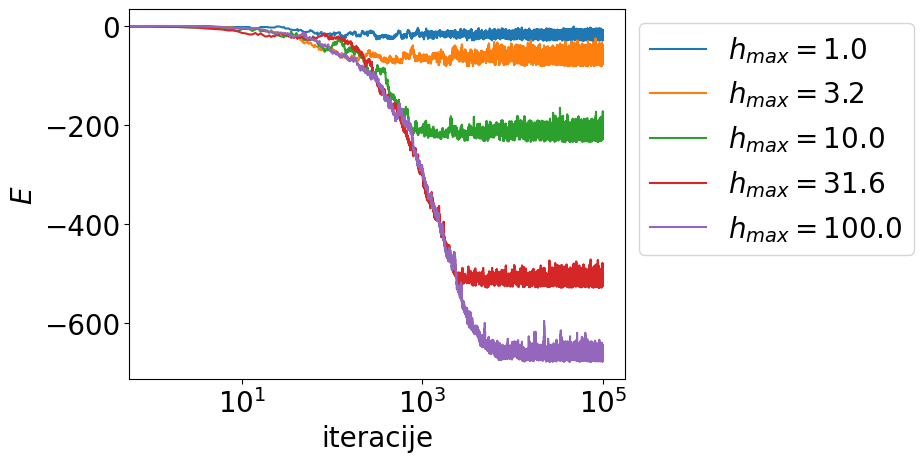

In [10]:
beta=1
alpha = 2
h_max0=np.logspace(0,2,5)
energija = []
oblika = np.array([])
iteracije = np.array([])
n = 100000
for h_max in h_max0:
    h=np.zeros(17)
    Ei = E(h,alpha)
    en=[E(h,alpha)]
    metropolis.counter=0
    for i in range(n):
        h, Ei = metropolis(h, Ei, alpha, beta, -h_max)
        en.append(Ei)
        if i%(n//10) == 0 and i!=0:
            oblika = np.append(oblika, h, axis=0)
            #iteracije = np.append(iteracije, i)
    oblika = np.append(oblika, h, axis=0)
    iteracije = np.append(iteracije, i)
    energija.append(en)
for i in range(len(energija)):
    plt.plot(energija[i], '-', label='$h_{max} = $'+str(round(h_max0[i],1)))
plt.legend(bbox_to_anchor=(1,1))
plt.xscale('log')
plt.xlabel('iteracije')
plt.ylabel('$E$')
#plt.savefig('slike/vpliv_h_max.pdf', bbox_inches='tight')

In [11]:
#ravnovesna lega, vplivi na sprejete poteze

vpliv začetnih pogojev

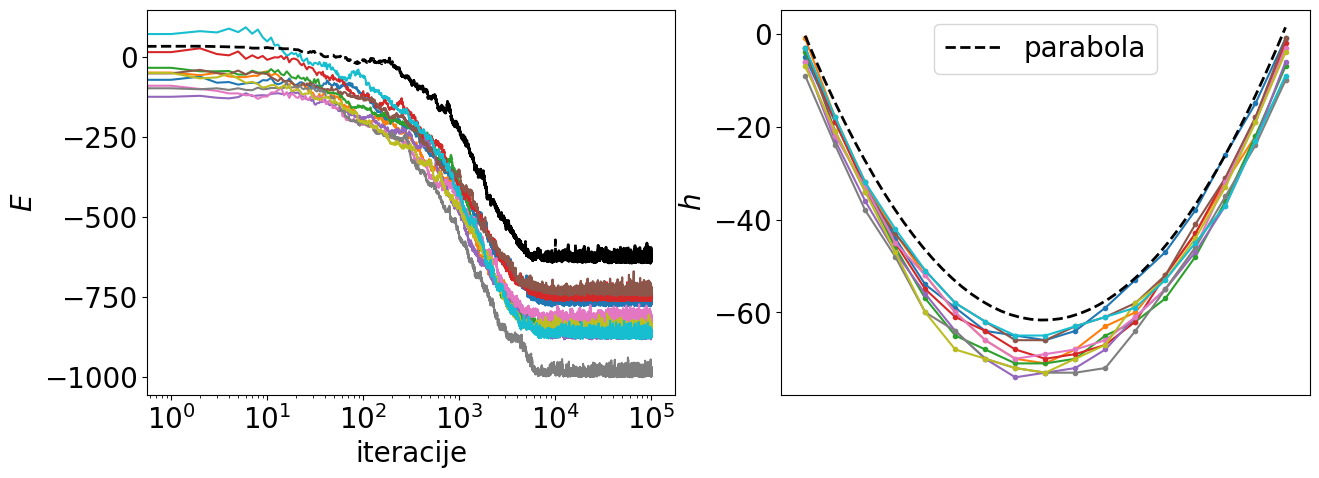

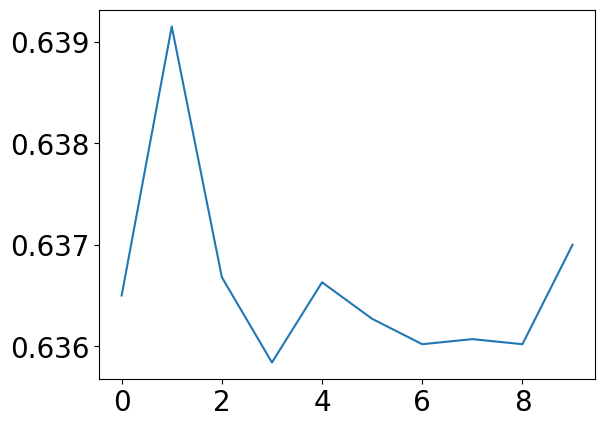

In [12]:
#naključna zač pozicija
alpha=2
beta=1
energija = []
oblika = []
iteracije = []
n = 100000
for j in range(10):
    h=np.random.randint(-10,0,size=17)
    #oblika.append(h)
    Ei = E(h,alpha)
    en=[E(h,alpha)]
    metropolis.counter=0
    for i in range(n):
        h, Ei = metropolis(h, Ei, alpha, beta, -np.inf)
        en.append(Ei)
    energija.append(en)
    oblika.append(h)
    iteracije.append(metropolis.counter)
h0=np.ones(len(h))
Ei = E(h0,alpha)
en=[E(h,alpha)]
for i in range(n):
    h0, Ei = metropolis(h0, Ei, alpha, beta, -np.inf)
    en.append(Ei)

fig, ax = plt.subplots(1,2,figsize=(15,5))
for i in range(len(energija)):
    ax[0].plot(energija[i], '-')
    ax[1].plot(oblika[i], '.-')
#plt.legend(bbox_to_anchor=(1,1))
ax[0].set_xscale('log')
ax[0].set_xlabel('iteracije')
ax[0].set_ylabel('$E$')
ax[1].set_xticks([]) 
ax[1].set_ylabel('$h$')
popt, _ = curve_fit(verižnica, np.array(range(len(h0))), h0)
x=np.linspace(0,len(h0)-1)
plt.plot(x, verižnica(x,*popt), 'k--', label=f'parabola', linewidth=2)
ax[0].plot(en, 'k--', linewidth=2)
plt.legend()
#plt.savefig('slike/vpliv_začetka.pdf', bbox_inches='tight')
plt.show()
plt.plot((n-np.array(iteracije))/n)

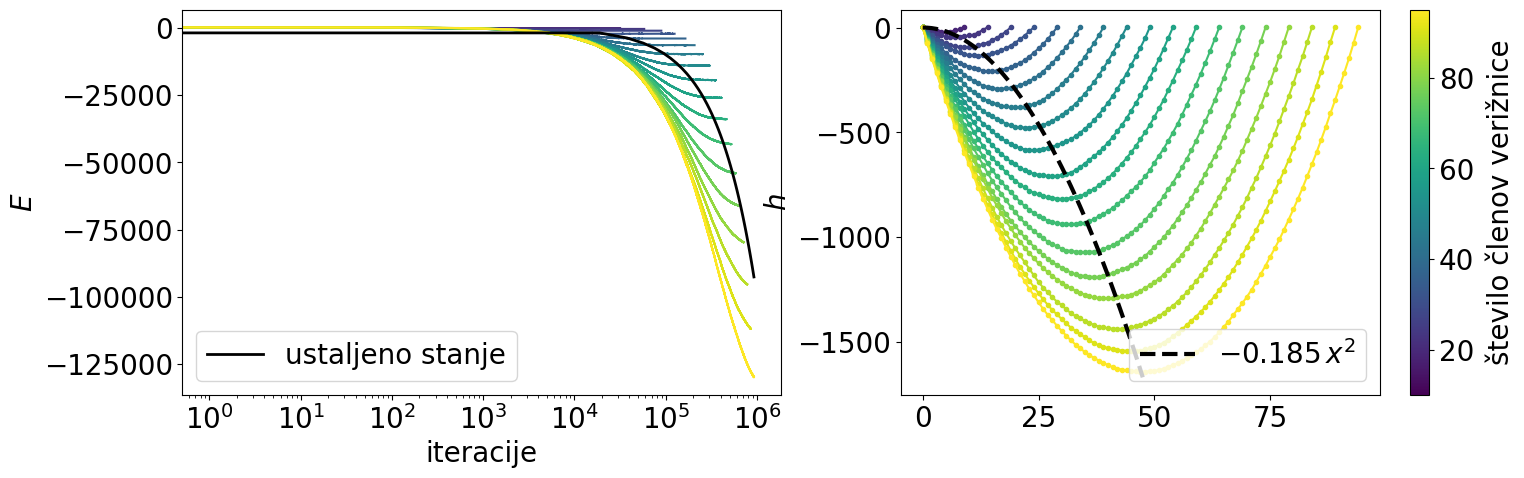

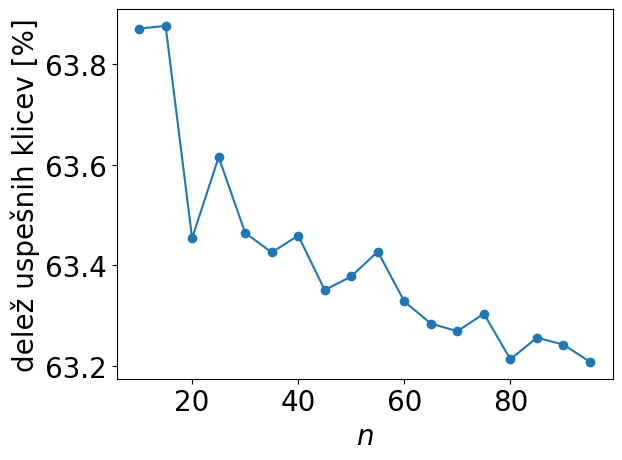

In [25]:
#različno število členov
alpha=2
beta=1
energija = []
oblika = []
iteracije = []
členi=np.arange(10, 100, 5, dtype=int)
cmap = plt.get_cmap('viridis')
fig, ax = plt.subplots(1,2,figsize=(17,5))
for j in členi:
    h=np.ones(j)
    #oblika.append(h)
    Ei = E(h,alpha)
    en=[E(h,alpha)]
    metropolis.counter=0
    n=int(1000*j**(1.5))
    for i in range(n):
        h, Ei = metropolis(h, Ei, alpha, beta, -np.inf)
        en.append(Ei)
    energija.append(en)
    oblika.append(h)
    iteracije.append(metropolis.counter)
    color_i = cmap(j / max(členi))
    ax[0].plot(en, '-', color=color_i)
    ax[1].plot(h, '.-', color=color_i)

popt, _ = curve_fit(verižnica, np.arange(0,len(h)), h)
a,b,c = popt
x = np.linspace(0, int(np.max(členi)))
ax[1].plot(x/2, min_verižnice(x,a), 'k--', label=f'$-{round(a/4,3)} \, x^2$', linewidth=3)
x=np.linspace(0, n)
ax[0].plot(x, -x/10, 'k-', label='ustaljeno stanje', linewidth=2)

sm = plt.cm.ScalarMappable(cmap=cmap, norm=plt.Normalize(vmin=min(členi), vmax=max(členi)))
sm.set_array([])
cbar = fig.colorbar(sm, ax=ax[1], orientation='vertical', label='število členov verižnice')
cbar.ax.yaxis.set_label_coords(4, 0.5)

ax[0].set_xscale('log')
ax[0].set_xlabel('iteracije')
ax[0].set_ylabel('$E$')
#ax[1].set_xticks([])
ax[1].set_ylabel('$h$')
ax[0].legend()
ax[1].legend()
#plt.savefig('slike/vpliv_dolžine.pdf', bbox_inches='tight')
plt.show()

plt.plot(členi, 100*(1000*np.array(členi)**(1.5)-np.array(iteracije))/(1000*np.array(členi)**(1.5)), 'o-')
plt.xlabel('$n$')
plt.ylabel('delež uspešnih klicev [%]')
#plt.savefig('slike/delež klicev_n.pdf', bbox_inches='tight')

vpliv alpha in beta na ravnovesje

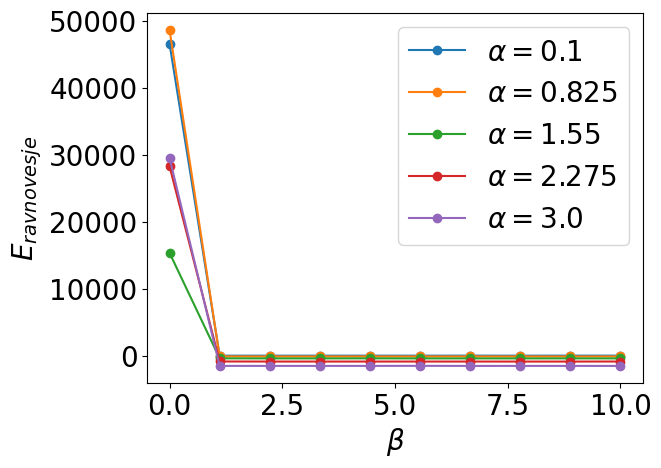

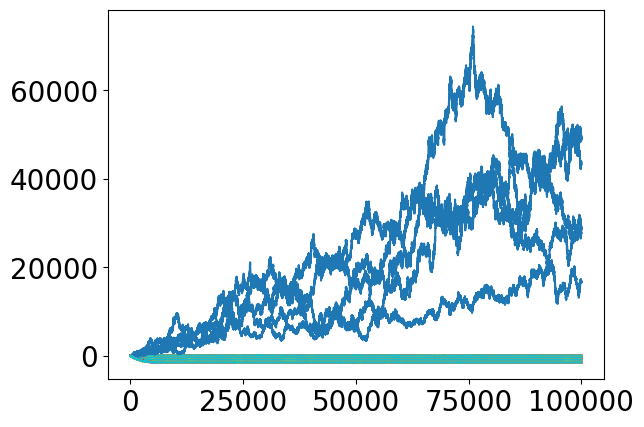

In [319]:
alpha0=np.linspace(0.1,3,5)
beta0=np.linspace(0,10,10)
energija = []
e_potek=[]
n = 10000
for alpha in alpha0:
    en1 = []
    for beta in beta0:
        h=np.zeros(17)
        Ei = E(h,alpha)
        en=[Ei]
        metropolis.counter=0
        for i in range(n):
            h, Ei = metropolis(h, Ei, alpha, beta, -np.inf)
            en.append(Ei)
        en1.append(ravnovesje(en))
        e_potek.append(en)
    energija.append(en1)

for i in range(len(alpha0)):
    plt.plot(beta0, energija[i], 'o-', label='$\\alpha=$'+str(alpha0[i]))
plt.legend(bbox_to_anchor=(1,1))
plt.xlabel('$\\beta$')
plt.ylabel('$E_{ravnovesje}$')
#plt.savefig('slike/vpliv_alpha.pdf', bbox_inches='tight')
plt.show()
for i in range(len(e_potek)):
    plt.plot(e_potek[i], '-')